# OASIS INFOBYTE Internship

## Task 3: Car Price Prediction with Machine Learning

**Objective:** To build machine learning models that predict the selling price of used cars based on their features.

**Author:** Vasuki S



## 1. Importing Libraries and Loading the Dataset

This step imports the required Python libraries and loads the car dataset for analysis and machine learning.



In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('/content/car data.csv')

display(df.head())
print("Dataset shape:", df.shape)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


Dataset shape: (301, 9)


## 2. Data Cleaning

Data cleaning removes duplicate records and standardises categorical values to maintain consistency. Missing values are also checked before further analysis.

In [20]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Standardise categorical values
text_columns = df.select_dtypes(include='object').columns

for col in text_columns:
    df[col] = df[col].str.strip().str.title()

# Check data quality
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())

Dataset shape: (299, 9)
Missing values: 0
Duplicate rows: 0


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,Ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,Sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,Ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,Wagon R,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,Swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Feature Engineering

Feature engineering creates useful features from existing data. Here, car age is calculated from the manufacturing year, and the car brand is extracted from the car name.

In [21]:
# Calculate car age
current_year = 2026
df['Car_Age'] = current_year - df['Year']

# Extract car brand from car name
df['Brand'] = df['Car_Name'].str.split().str[0]

display(df[['Car_Name', 'Year', 'Car_Age', 'Brand']].head())

,Car_Name,Year,Car_Age,Brand
0,Ritz,2014,12,Ritz
1,Sx4,2013,13,Sx4
2,Ciaz,2017,9,Ciaz
3,Wagon R,2011,15,Wagon
4,Swift,2014,12,Swift


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of Selling Prices

This analysis shows how the selling prices of used cars are distributed and identifies common price ranges.

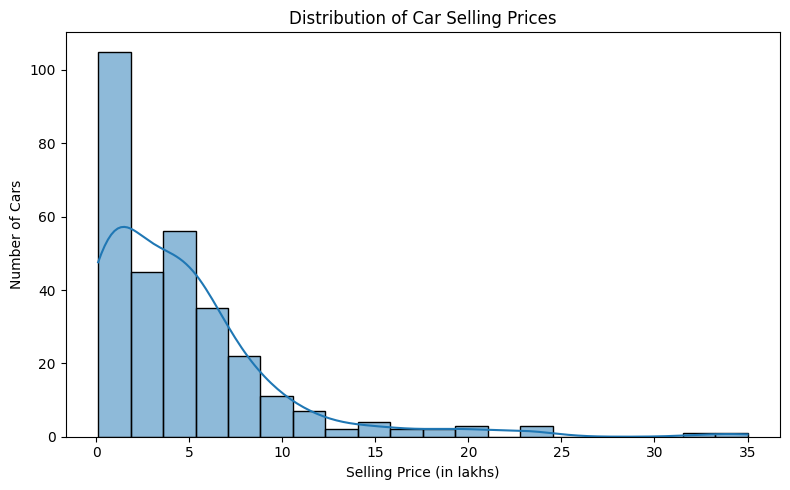

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Selling_Price', bins=20, kde=True)
plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price (in lakhs)')
plt.ylabel('Number of Cars')
plt.tight_layout()
plt.show()

### 4.2 Selling Price vs Fuel Type

This box plot compares car selling prices across different fuel types and shows their price variation.

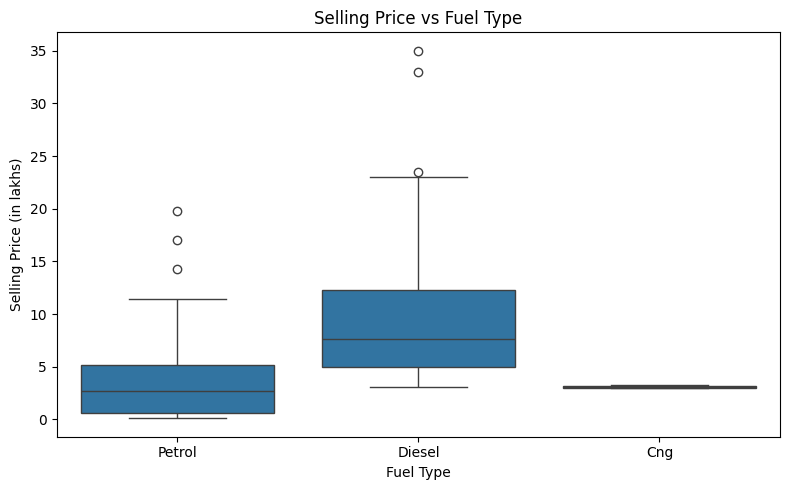

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price')
plt.title('Selling Price vs Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price (in lakhs)')
plt.tight_layout()
plt.show()

### 4.3 Selling Price vs Car Age

This scatter plot examines the relationship between car age and selling price.

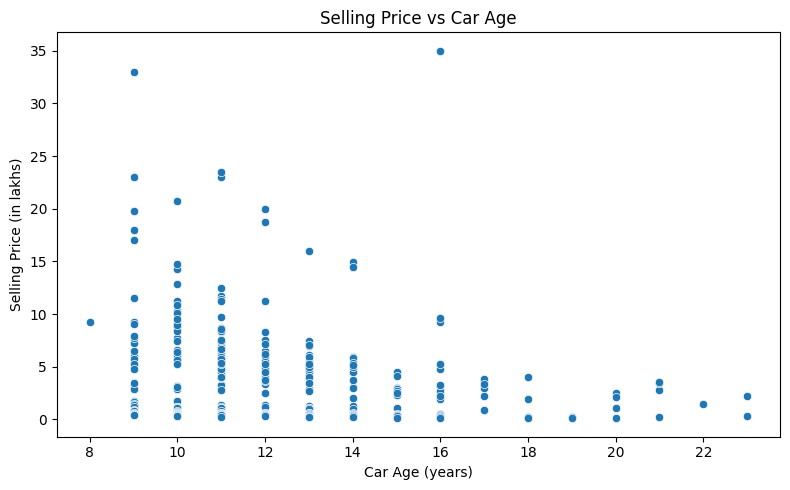

In [24]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Car_Age', y='Selling_Price')
plt.title('Selling Price vs Car Age')
plt.xlabel('Car Age (years)')
plt.ylabel('Selling Price (in lakhs)')
plt.tight_layout()
plt.show()

## 5. Feature Correlation Heatmap

A correlation heatmap shows the relationships between numerical features. It helps us understand which features are associated with car selling prices.

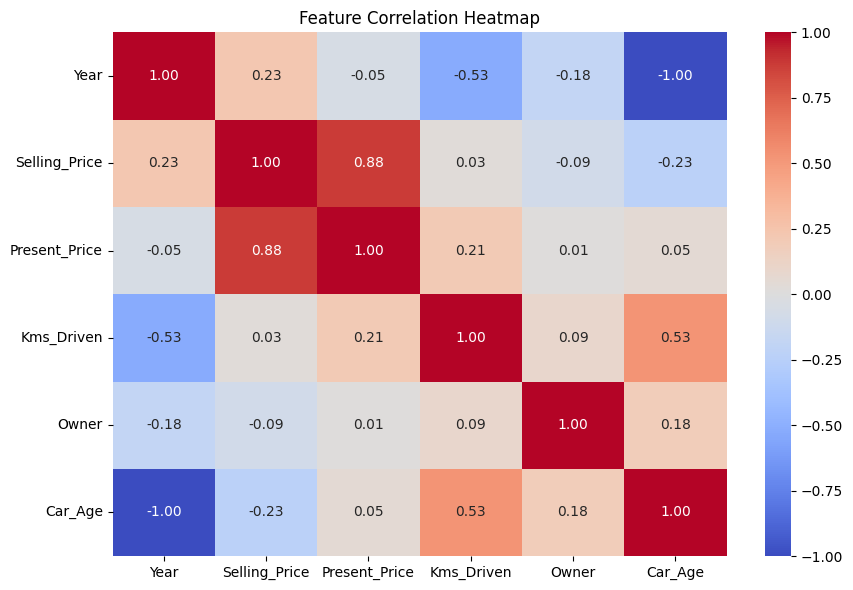

In [25]:
plt.figure(figsize=(9, 6))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

Data preprocessing converts categorical features into numerical form so that machine learning models can use them. The target variable is the selling price of the car.

In [26]:
# Remove the target and original car name from input features
X = df.drop(columns=['Selling_Price', 'Car_Name'])

# Encode categorical variables using one-hot encoding
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Define the target variable
y = df['Selling_Price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (299, 52)
Target shape: (299,)


,Year,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual,Brand_Activa,...,Brand_Suzuki,Brand_Swift,Brand_Sx4,Brand_Tvs,Brand_Um,Brand_Verna,Brand_Vitara,Brand_Wagon,Brand_Xcent,Brand_Yamaha
0,2014,5.59,27000,0,12,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2013,9.54,43000,0,13,1,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0
2,2017,9.85,6900,0,9,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,2011,4.15,5200,0,15,0,1,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,2014,6.87,42450,0,12,1,0,0,1,0,...,0,1,0,0,0,0,0,0,0,0


## 7. Train-Test Split

The dataset is divided into training and testing sets. The training set is used to build the models, while the testing set evaluates their performance on unseen data.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 239
Testing samples: 60


## 8. Model Training and Evaluation

Two regression models, Linear Regression and Random Forest Regressor, are trained to predict car selling prices. Their performance is compared using MAE, RMSE and R² score to identify the better-performing model.

In [28]:
# Train Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

# Train Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

# Evaluate both models
results = []

for name, predictions in [
    ("Linear Regression", lr_predictions),
    ("Random Forest", rf_predictions)
]:
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

# Select the best model based on R2 score
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(), "Model"
]

best_model = (
    lr_model if best_model_name == "Linear Regression"
    else rf_model
)

print("Best-performing model:", best_model_name)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.809,3.399,0.552
1,Random Forest,1.430,3.551,0.511


Best-performing model: Linear Regression


## 9. Feature Importance

Feature importance identifies the input features that contribute most to predictions made by the best-performing model. This helps us understand which car characteristics influence predicted selling prices.

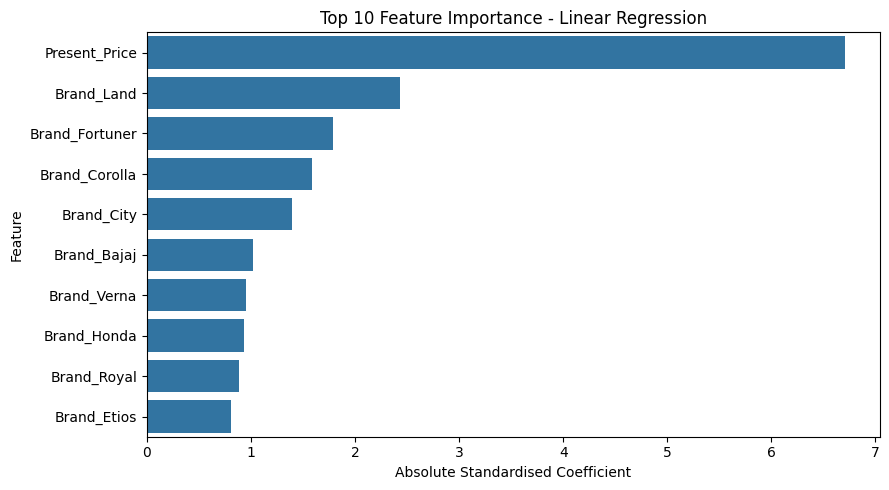

In [29]:
# Feature importance using the selected Linear Regression model
from sklearn.preprocessing import StandardScaler

# Standardise features to compare coefficient magnitudes
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train Linear Regression on scaled features
lr_scaled_model = LinearRegression()
lr_scaled_model.fit(X_train_scaled, y_train)

# Calculate feature importance using absolute coefficients
importance = np.abs(lr_scaled_model.coef_)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(
    by="Importance", ascending=False
).head(10)

# Plot the top 10 important features
plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Linear Regression")
plt.xlabel("Absolute Standardised Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 10. Predicting the Selling Price of a New Car

This section uses the best-performing trained model to predict the selling price of a sample car based on its features.

In [30]:
# Create details for a sample car
new_car = pd.DataFrame([{
    'Car_Name': 'city',
    'Year': 2017,
    'Selling_Price': 0,
    'Present_Price': 8.5,
    'Kms_Driven': 25000,
    'Fuel_Type': 'Petrol',
    'Seller_Type': 'Dealer',
    'Transmission': 'Manual',
    'Owner': 0
}])

# Create engineered features
new_car['Car_Age'] = 2026 - new_car['Year']
new_car['Brand'] = new_car['Car_Name'].str.split().str[0].str.title()

# Prepare the input using the same encoding as the training data
new_car_features = new_car.drop(
    columns=['Selling_Price', 'Car_Name']
)
new_car_encoded = pd.get_dummies(
    new_car_features, drop_first=True, dtype=int
)
new_car_encoded = new_car_encoded.reindex(
    columns=X.columns, fill_value=0
)

# Predict the selling price
predicted_price = best_model.predict(new_car_encoded)[0]

print("Sample car: Honda City")
print("Year: 2017")
print("Present price: ₹8.5 lakhs")
print("Kilometres driven: 25,000")
print(f"Predicted selling price: ₹{predicted_price:.2f} lakhs")

Sample car: Honda City
Year: 2017
Present price: ₹8.5 lakhs
Kilometres driven: 25,000
Predicted selling price: ₹10.87 lakhs


## 11. Final Validation

Final validation checks the dataset quality, confirms that both regression models were trained, and verifies that evaluation metrics and the sample prediction are available.

In [31]:
print("FINAL PROJECT VALIDATION")
print("-" * 35)

# Dataset checks
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Model checks
print("\nModels trained:")
print(results_df['Model'].tolist())

# Evaluation metrics
print("\nModel evaluation results:")
display(results_df.round(3))

# Prediction check
print("\nPredicted price:", round(float(predicted_price), 2), "lakhs")
print("Prediction is finite:", np.isfinite(predicted_price))

# Final status
checks_passed = (
    df.isnull().sum().sum() == 0
    and df.duplicated().sum() == 0
    and len(results_df) >= 2
    and results_df[['MAE', 'RMSE', 'R2 Score']].notnull().all().all()
    and np.isfinite(predicted_price)
)

print("\nStatus:", "PASSED" if checks_passed else "CHECK REQUIRED")

FINAL PROJECT VALIDATION
-----------------------------------
Dataset shape: (299, 11)
Missing values: 0
Duplicate rows: 0

Models trained:
['Linear Regression', 'Random Forest']

Model evaluation results:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.809,3.399,0.552
1,Random Forest,1.430,3.551,0.511



Predicted price: 10.87 lakhs
Prediction is finite: True

Status: PASSED


## 12. Conclusion

This project analysed used car prices and developed two regression models: Linear Regression and Random Forest Regressor. Their performance was evaluated using MAE, RMSE and R² score. Feature importance was examined to identify influential features, and the selected model was used to predict the selling price of a sample car. This project demonstrates how machine learning can support used car price estimation.